In [ ]:
# JERICHON import bootstrap (shared resolver in src/project_paths.py)
from pathlib import Path
import os, sys

# Locate repository from the current working directory or its parents.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for _base in list(_candidates):
    try:
        _candidates.extend(_child for _child in _base.iterdir() if _child.is_dir())
    except (OSError, PermissionError):
        pass
PROJECT_ROOT = next((p.resolve() for p in _candidates
                     if (p / "src" / "__init__.py").is_file()
                     and (p / "src" / "data" / "builders").is_dir()), None)
if PROJECT_ROOT is None:
    _env_root = os.environ.get("JERICHON_PROJECT_ROOT")
    if _env_root:
        _candidate = Path(_env_root).expanduser().resolve()
        if (_candidate / "src" / "__init__.py").is_file():
            PROJECT_ROOT = _candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень JERICHON. Откройте VS Code в папке репозитория "
        "или задайте JERICHON_PROJECT_ROOT.")
if str(PROJECT_ROOT) in sys.path:
    sys.path.remove(str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_paths import bootstrap_project, find_project_root
PROJECT_ROOT = bootstrap_project(PROJECT_ROOT)


# JERICHON — Extremums & Reversal Research

Цель — исследовать локальные экстремумы и вероятность разворота, а не просто классифицировать следующий бар как UP/DOWN.

Notebook сравнивает:
1. **Directional Change / ZigZag** — экстремум подтверждается, когда цена откатывает на заданный процент от текущего максимума/минимума.
2. **Rolling fractals** — экстремумы в окне `2 × radius + 1`; точка экстремума и момент, когда она становится известна, разделены.
3. **Pre-confirmation prediction** — вероятность достижения обратного барьера раньше барьера продолжения в ближайшие `H` Dollar Bars.
4. **Post-event outcomes** — MFE/MAE, частота достижения 0,5%, 1%, 1,5%, 2% и время до цели.

Будущие цены используются только для исторических labels/outcomes. Признаки берутся из канонического JERICHON feature pipeline и должны быть доступны к `bar_ts`. Все данные читаются из локального AlgoPack-архива; сетевые API-вызовы не используются.

## 0. Конфигурация

Варьируем `THETAS` (минимальный размер обратного движения), `HORIZONS` (горизонт в Dollar Bars) и `MOVE_TARGETS` (потенциальное движение). Сначала исследуем статистику и устойчивость, а не оптимизируем параметры по доходности.

In [ ]:
from pathlib import Path
import sys, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use('cyberpunk')
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_score, recall_score, balanced_accuracy_score

TICKER = "SMLT"
DOLLAR_THRESHOLD = 10_000_000
EXPECTED_FEATURES = 474
THETAS = [0.005, 0.0075, 0.01, 0.015, 0.02]
HORIZONS = [5, 10, 25, 50]
MOVE_TARGETS = [0.005, 0.01, 0.015, 0.02]
TREND_LOOKBACK = 10
FRACTAL_RADII = [2, 3, 5]
TEST_FRACTION = 0.30
RANDOM_STATE = 42

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    # Common explicit fallback: edit this if notebook is outside the repository.
    fallback = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON")
    if (fallback / "data" / "for_ml" / "storage" / "history").exists():
        return fallback
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную в этой ячейке."
    )

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / "data"
HISTORY_ROOT = DATA_ROOT / "for_ml" / "storage" / "history"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.builders import jerichon_feature_pipeline as jfp

## 1. Загрузка локальной истории AlgoPack

Структура сохранена как в reference notebook: `realtime/{TICKER}/{date}/trades.parquet` и `supercandles/{TICKER}/{date}/{tradestats,obstats,orderstats}.parquet`. Orderbook не включаем в Super Candle features. Если источников не хватает, notebook останавливается и не пытается обратиться к API.

In [2]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)
    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy(); x["file_date"] = day; frames[key].append(x)
                except Exception as exc:
                    print(f"WARNING: {p}: {exc}")
        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy(); x["file_date"] = day; frames[key].append(x)
                except Exception as exc:
                    print(f"WARNING: {p}: {exc}")
    out = {k: pd.concat(v, ignore_index=True) if v else pd.DataFrame() for k, v in frames.items()}
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников {missing}; API-вызов не выполняется.")
    print(f"Saved dates: {len(dates)} | {dates[0]} → {dates[-1]}")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

,source,rows
0,candles,12515
1,trades,612199
2,orderbook,280
3,tradestats,2520
4,obstats,2450
5,orderstats,2534


Saved dates: 14 | 2026-09-25 → 2026-10-20


## 2. Dollar Bars + 474 признака

Используем локальные helper-функции канонического `jerichon_feature_pipeline.py`, а не публичный builder, который может создавать provider/API-клиент. Проверяем inventory: 73 base + 401 Super Candle = 474 ML features.

In [3]:
required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_attach_source")
missing_helpers = [n for n in required_helpers if not hasattr(jfp, n)]
if missing_helpers:
    raise RuntimeError(f"В jerichon_feature_pipeline.py отсутствуют helper-функции: {missing_helpers}")

bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Нормализуем временную ось, не меняя исходные данные.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"Нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (
    bars.dropna(subset=["bar_ts"])
        .sort_values("bar_ts")
        .drop_duplicates("bar_ts", keep="last")
        .reset_index(drop=True)
)
print("Dollar Bars:", len(bars), "|", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
print("Dollar Bar columns:", list(bars.columns))

# _base в текущем jerichon_feature_pipeline добавляет много столбцов по одному.
# Подавляем только его шумный PerformanceWarning и сразу дефрагментируем результат.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=pd.errors.PerformanceWarning)
    base_frame = jfp._base(bars.copy())
base_frame = base_frame.copy()

if "bar_ts" not in base_frame.columns:
    if len(base_frame) != len(bars):
        raise RuntimeError("_base output has no bar_ts and row count differs from bars.")
    base_frame["bar_ts"] = bars["bar_ts"].values

base_cols = [c for c in base_frame.columns if c.startswith("base__")]
if not base_cols:
    excluded = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
    base_cols = [
        c for c in base_frame.columns
        if c not in excluded and pd.api.types.is_numeric_dtype(base_frame[c])
    ]
if len(base_cols) != 73:
    raise RuntimeError(f"Base inventory mismatch: {len(base_cols)}; expected 73.")

raw_sc = {k: data[k] for k in ("tradestats", "obstats", "orderstats")}

# _build_sc_features в установленной версии pipeline ожидает `ts` и `CLOSE`,
# а Dollar Bars здесь имеют канонические `bar_ts` и `close`. Даём helper'у
# совместимую копию с алиасами; production-данные и bars не переименовываем.
bars_for_sc = bars.copy()
if "ts" not in bars_for_sc.columns:
    bars_for_sc["ts"] = bars_for_sc["bar_ts"]
if "CLOSE" not in bars_for_sc.columns:
    if "close" not in bars_for_sc.columns:
        raise RuntimeError(
            "Для Super Candle features нужен CLOSE/close. "
            f"Доступные колонки: {list(bars_for_sc.columns)}"
        )
    bars_for_sc["CLOSE"] = bars_for_sc["close"]

# На случай, если конкретная версия helper'а использует и остальные OHLCV
# имена в верхнем регистре.
for lower, upper in (("open", "OPEN"), ("high", "HIGH"), ("low", "LOW"), ("volume", "VOLUME")):
    if upper not in bars_for_sc.columns and lower in bars_for_sc.columns:
        bars_for_sc[upper] = bars_for_sc[lower]

sc_frames = jfp._build_sc_features(raw_sc, bars_for_sc)
if not isinstance(sc_frames, dict):
    raise TypeError(f"_build_sc_features returned {type(sc_frames)}, expected dict.")
print("Base features:", len(base_cols))
print("Super Candle groups:", list(sc_frames))

Dollar Bars: 2672 | 2026-09-25 04:03:05+00:00 → 2026-10-20 18:33:55+00:00
Dollar Bar columns: ['open', 'high', 'low', 'close', 'volume', 'value', 'count', 'open_time', 'close_time', 'bar_ts']
Base features: 73
Super Candle groups: ['tradestats', 'orderstats', 'obstats']


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

## 3. Causal join

Каждая Super Candle запись может участвовать в признаках только если её `event_ts` и валидированный `available_at` не позже времени решения. Никакого join по простому совпадению `ts`; `orderbook` остаётся отдельным источником.

In [4]:
causal = bars[["bar_ts"]].copy()
for source in ("tradestats", "obstats", "orderstats"):
    if source not in sc_frames or sc_frames[source] is None or sc_frames[source].empty:
        raise RuntimeError(f"Нет Super Candle feature frame для {source}")
    causal = jfp._attach_source(causal, sc_frames[source], data[source], source)
    if causal is None or causal.empty:
        raise RuntimeError(f"_attach_source вернул пустой результат для {source}")

base_join = base_frame.copy()
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

provenance_cols = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [c for c in causal.columns if c.startswith(sc_prefixes) and c not in provenance_cols and pd.api.types.is_numeric_dtype(causal[c])]
feature_cols = base_cols + sc_feature_cols
if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(f"Feature inventory mismatch: {len(feature_cols)}; expected {EXPECTED_FEATURES}.")
if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Duplicate ML feature names.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy().sort_values("bar_ts").reset_index(drop=True)
print("FINAL_DATASET:", FINAL_DATASET.shape, "| ML features:", len(feature_cols), "| provenance:", len(provenance_cols))
display((FINAL_DATASET[feature_cols].isna().mean().sort_values(ascending=False).head(10)*100).to_frame("missing_%"))

FINAL_DATASET: (2672, 481) | ML features: 474 | provenance: 6


,missing_%
tradestats__ts_flow_x_return_ret,16.803892
tradestats__ts_vwap_b_s_bps_ret,15.344311
obstats__ob_val_imb_bbo_vs_deep_ret,2.058383
obstats__ob_vol_imb_bbo_vs_deep_ret,1.646707
tradestats__ts_trade_imbalance_ret,0.673653
orderstats__os_put_vwap_b_s_bps_ret,0.449102
orderstats__os_put_orders_imb_ret,0.299401
tradestats__ts_vwap_b_s_bps_ma3,0.261976
tradestats__ts_vwap_b_s_bps_z3,0.261976
tradestats__ts_vwap_b_s_bps_chg,0.224551


## 4. Подготовка цен

Используем Dollar Bar `close/high/low`. Будущие `high/low` попадут только в labels и outcome calculations, не в `X`.

In [5]:
for col in ("open", "high", "low", "close"):
    if col not in bars.columns:
        raise RuntimeError(f"В Dollar Bars отсутствует {col}.")
market = bars[["bar_ts", "open", "high", "low", "close"]].copy()
market["bar_ts"] = pd.to_datetime(market["bar_ts"], utc=True)
market = market.merge(FINAL_DATASET[["bar_ts"] + feature_cols], on="bar_ts", how="inner", validate="one_to_one")
market = market.sort_values("bar_ts").reset_index(drop=True)
bar_ts = market["bar_ts"]
price = market["close"].astype(float)
high = market["high"].astype(float)
low = market["low"].astype(float)
X_raw = market[feature_cols].replace([np.inf, -np.inf], np.nan)
print("Aligned rows:", len(market), "| feature count:", X_raw.shape[1])
display(market[["bar_ts", "close", "high", "low"]].head())

Aligned rows: 2672 | feature count: 474


,bar_ts,close,high,low
0,2026-09-25 04:03:05+00:00,252.2,252.2,251.0
1,2026-09-25 04:16:20+00:00,251.6,252.2,251.0
2,2026-09-25 04:33:18+00:00,251.0,251.8,250.6
3,2026-09-25 04:35:39+00:00,250.4,251.0,250.2
4,2026-09-25 04:40:43+00:00,250.0,250.6,249.8


## 5. Метод A — Directional Change / ZigZag

Восходящий тренд: отслеживаем максимум; если цена откатывает от него на `theta`, максимум становится подтверждённой вершиной. Для минимума симметрично. `pivot_ts` — время самого экстремума; `confirm_ts` — время, когда откат стал достаточным. Для реальной торговли экстремум нельзя считать известным до `confirm_ts`.

In [6]:
def directional_change_events(close_series, theta):
    p = pd.Series(close_series).astype(float).reset_index(drop=True).to_numpy()
    events = []
    if len(p) < 3:
        return pd.DataFrame()
    trend, extreme_i, extreme_p = 0, 0, p[0]
    for i in range(1, len(p)):
        x = p[i]
        if not np.isfinite(x) or x <= 0 or not np.isfinite(extreme_p) or extreme_p <= 0:
            continue
        if trend == 0:
            if x >= p[0] * (1 + theta):
                trend, extreme_i, extreme_p = 1, i, x
            elif x <= p[0] * (1 - theta):
                trend, extreme_i, extreme_p = -1, i, x
            elif x > extreme_p or x < extreme_p:
                extreme_i, extreme_p = i, x
            continue
        if trend == 1:
            if x >= extreme_p:
                extreme_i, extreme_p = i, x
            elif x <= extreme_p * (1 - theta):
                events.append({"pivot_idx": extreme_i, "confirm_idx": i, "side": "peak",
                               "pivot_price": extreme_p, "confirm_price": x, "theta": theta})
                trend, extreme_i, extreme_p = -1, i, x
        else:
            if x <= extreme_p:
                extreme_i, extreme_p = i, x
            elif x >= extreme_p * (1 + theta):
                events.append({"pivot_idx": extreme_i, "confirm_idx": i, "side": "trough",
                               "pivot_price": extreme_p, "confirm_price": x, "theta": theta})
                trend, extreme_i, extreme_p = 1, i, x
    out = pd.DataFrame(events)
    if len(out):
        out["pivot_ts"] = bar_ts.iloc[out["pivot_idx"]].to_numpy()
        out["confirm_ts"] = bar_ts.iloc[out["confirm_idx"]].to_numpy()
        out["confirmation_delay_bars"] = out["confirm_idx"] - out["pivot_idx"]
        out["leg_return_pct"] = out["pivot_price"].pct_change() * 100
    return out

dc_events = {theta: directional_change_events(price, theta) for theta in THETAS}
dc_summary = pd.DataFrame([{
    "theta_%": theta*100, "events": len(ev),
    "peaks": int((ev["side"] == "peak").sum()) if len(ev) else 0,
    "troughs": int((ev["side"] == "trough").sum()) if len(ev) else 0,
    "median_confirmation_delay_bars": ev["confirmation_delay_bars"].median() if len(ev) else np.nan,
    "median_abs_leg_return_%": ev["leg_return_pct"].abs().median() if len(ev) else np.nan
} for theta, ev in dc_events.items()])
display(dc_summary)

,theta_%,events,peaks,troughs,median_confirmation_delay_bars,median_abs_leg_return_%
0,0.50,299,149,150,2.0,1.107171
1,0.75,187,93,94,4.0,1.426174
2,1.00,124,62,62,7.0,1.811907
3,1.50,57,28,29,12.0,2.906468
4,2.00,39,19,20,20.0,3.421607


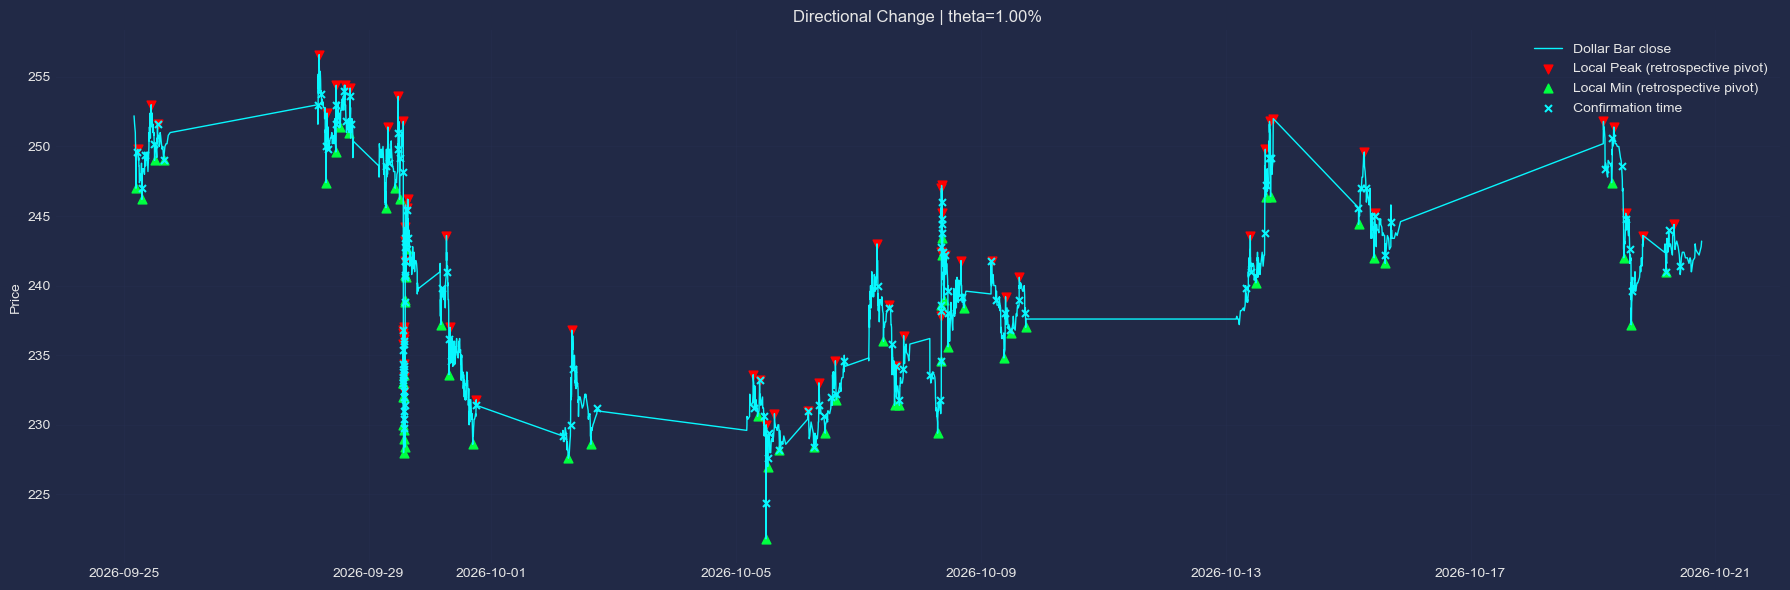

In [11]:
PLOT_THETA = 0.01
ev = dc_events[PLOT_THETA]
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(bar_ts, price, linewidth=1, label="Dollar Bar close")
if len(ev):
    peaks, troughs = ev[ev.side == "peak"], ev[ev.side == "trough"]
    ax.scatter(peaks.pivot_ts, peaks.pivot_price, marker="v", color='C4', s=40, label="Local Peak (retrospective pivot)")
    ax.scatter(troughs.pivot_ts, troughs.pivot_price, marker="^", color='C3', s=40, label="Local Min (retrospective pivot)")
    ax.scatter(ev.confirm_ts, ev.confirm_price, marker="x", s=25, label="Confirmation time")
ax.set_title(f"Directional Change | theta={PLOT_THETA:.2%}")
ax.set_ylabel("Price"); ax.grid(True, alpha=.25); ax.legend()
plt.tight_layout(); plt.show()

## 6. Метод B — rolling fractals

Локальный максимум/минимум в симметричном окне. Центральная точка становится известна только через `radius` баров справа. Это полезно для сравнения частоты/масштаба экстремумов, но не означает, что точку можно было торговать в момент её образования.

In [12]:
def rolling_fractals(close_series, radius=3):
    p = pd.Series(close_series).astype(float).reset_index(drop=True)
    rows = []
    for i in range(radius, len(p)-radius):
        w, x = p.iloc[i-radius:i+radius+1], p.iloc[i]
        if x == w.max() and (w == x).sum() == 1:
            rows.append({"pivot_idx": i, "confirm_idx": i+radius, "side": "peak", "pivot_price": x})
        if x == w.min() and (w == x).sum() == 1:
            rows.append({"pivot_idx": i, "confirm_idx": i+radius, "side": "trough", "pivot_price": x})
    out = pd.DataFrame(rows)
    if len(out):
        out["pivot_ts"] = bar_ts.iloc[out.pivot_idx].to_numpy()
        out["confirm_ts"] = bar_ts.iloc[out.confirm_idx].to_numpy()
        out["confirmation_delay_bars"] = radius
    return out

fractal_events = {r: rolling_fractals(price, r) for r in FRACTAL_RADII}
fractal_summary = pd.DataFrame([{
    "radius": r, "events": len(ev),
    "peaks": int((ev.side == "peak").sum()) if len(ev) else 0,
    "troughs": int((ev.side == "trough").sum()) if len(ev) else 0,
    "confirmation_delay_bars": r
} for r, ev in fractal_events.items()])
display(fractal_summary)

,radius,events,peaks,troughs,confirmation_delay_bars
0,2,530,266,264,2
1,3,374,192,182,3
2,5,227,113,114,5


## 7. Pre-confirmation target: обратный барьер раньше барьера продолжения

Для каждого бара определяем направление предыдущего движения по доходности за `TREND_LOOKBACK`. Если тренд вверх, reversal barrier — `-theta`, continuation barrier — `+theta`; для нисходящего тренда наоборот. Target = 1, если обратный барьер достигнут первым в ближайшие `H` баров.

Если оба барьера затронуты внутри одного OHLC-бара, точный порядок неизвестен; консервативно присваиваем 0. Это не «истинная метка экстремума», а проверяемая гипотеза о раннем распознавании обратного движения.

In [13]:
def first_barrier_label(close_s, high_s, low_s, lookback, theta, horizon):
    c, h, l = [pd.Series(x).astype(float).reset_index(drop=True) for x in (close_s, high_s, low_s)]
    trend = np.sign((c / c.shift(lookback) - 1).to_numpy())
    n = len(c)
    y = np.full(n, np.nan)
    trend_dir = np.zeros(n, dtype=int)
    reversal_excursion = np.full(n, np.nan)
    continuation_excursion = np.full(n, np.nan)
    bars_to_hit = np.full(n, np.nan)
    for i in range(lookback, n-horizon):
        if not np.isfinite(c.iloc[i]) or c.iloc[i] <= 0 or trend[i] == 0:
            continue
        d, entry = int(trend[i]), c.iloc[i]
        trend_dir[i] = d
        rev_hits, cont_hits = [], []
        for j in range(i+1, i+horizon+1):
            if d > 0:
                if l.iloc[j] <= entry*(1-theta): rev_hits.append(j)
                if h.iloc[j] >= entry*(1+theta): cont_hits.append(j)
            else:
                if h.iloc[j] >= entry*(1+theta): rev_hits.append(j)
                if l.iloc[j] <= entry*(1-theta): cont_hits.append(j)
        rf = rev_hits[0] if rev_hits else None
        cf = cont_hits[0] if cont_hits else None
        y[i] = int(rf is not None and (cf is None or rf < cf))
        if y[i] == 1: bars_to_hit[i] = rf-i
        fh, fl = h.iloc[i+1:i+horizon+1], l.iloc[i+1:i+horizon+1]
        if d > 0:
            reversal_excursion[i] = max(0., (entry-fl.min())/entry)
            continuation_excursion[i] = max(0., (fh.max()-entry)/entry)
        else:
            reversal_excursion[i] = max(0., (fh.max()-entry)/entry)
            continuation_excursion[i] = max(0., (entry-fl.min())/entry)
    return pd.DataFrame({"trend_direction": trend_dir, "reversal_first": y,
                         "reversal_excursion": reversal_excursion,
                         "continuation_excursion": continuation_excursion,
                         "bars_to_reversal_hit": bars_to_hit})

print("Target function ready.")

Target function ready.


## 8. Descriptive sweep: вероятность и скорость обратного движения

Сравниваем пороги и горизонты до обучения. Важно оценивать и частоту события, и размер потенциального движения: много событий не обязательно означает полезную стратегию.

In [14]:
barrier_rows = []
for theta in THETAS:
    for horizon in HORIZONS:
        lab = first_barrier_label(price, high, low, TREND_LOOKBACK, theta, horizon)
        valid = lab.reversal_first.notna()
        y = lab.loc[valid, "reversal_first"]
        barrier_rows.append({
            "theta_%": theta*100, "horizon_bars": horizon,
            "eligible_n": int(valid.sum()),
            "reversal_first_rate_%": y.mean()*100 if len(y) else np.nan,
            "median_reversal_excursion_%": lab.loc[valid, "reversal_excursion"].median()*100 if len(y) else np.nan,
            "median_continuation_excursion_%": lab.loc[valid, "continuation_excursion"].median()*100 if len(y) else np.nan,
            "median_bars_to_reversal": lab.loc[valid, "bars_to_reversal_hit"].median() if lab.loc[valid, "bars_to_reversal_hit"].notna().any() else np.nan
        })
barrier_stats = pd.DataFrame(barrier_rows)
display(barrier_stats)

,theta_%,horizon_bars,eligible_n,reversal_first_rate_%,median_reversal_excursion_%,median_continuation_excursion_%,median_bars_to_reversal
0,0.50,5,2550,35.960784,0.395883,0.344531,3.0
1,0.50,10,2545,47.937132,0.553360,0.515464,3.0
2,0.50,25,2531,51.481628,0.873016,0.784314,4.0
3,0.50,50,2509,51.375050,1.225919,1.192369,4.0
4,0.75,5,2550,18.235294,0.395883,0.344531,4.0
5,0.75,10,2545,35.402750,0.553360,0.515464,5.0
6,0.75,25,2531,50.493876,0.873016,0.784314,7.0
7,0.75,50,2509,52.251893,1.225919,1.192369,7.0
8,1.00,5,2550,7.215686,0.395883,0.344531,4.0
9,1.00,10,2545,21.571709,0.553360,0.515464,7.0


## 9. Baseline ML: ExtraTrees + хронологический holdout

Обучаем на ранней части ряда, тестируем на поздней. Импутация обучается только на train. Смотрим PR-AUC относительно prevalence, ROC-AUC, Brier score, precision/recall. Это baseline, не доказательство альфы: нужно будет повторить на walk-forward и независимом test.

In [15]:
def fit_reversal_baseline(X, y, test_fraction=.30):
    valid = y.notna()
    Xv, yv = X.loc[valid].reset_index(drop=True), y.loc[valid].astype(int).reset_index(drop=True)
    if len(yv) < 300 or yv.nunique() < 2:
        return None, {"status": "insufficient data/classes", "n": len(yv), "classes": yv.nunique()}
    split = int(len(yv)*(1-test_fraction))
    X_train, X_test, y_train, y_test = Xv.iloc[:split], Xv.iloc[split:], yv.iloc[:split], yv.iloc[split:]
    if y_train.nunique() < 2 or y_test.nunique() < 2:
        return None, {"status": "single class in train/test", "n_train": len(y_train), "n_test": len(y_test)}
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", ExtraTreesClassifier(n_estimators=300, min_samples_leaf=8, max_features="sqrt",
                                      class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
    ])
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= .5).astype(int)
    metrics = {
        "status": "ok", "n_train": len(y_train), "n_test": len(y_test),
        "train_prevalence_%": y_train.mean()*100, "test_prevalence_%": y_test.mean()*100,
        "roc_auc": roc_auc_score(y_test, prob), "pr_auc": average_precision_score(y_test, prob),
        "brier": brier_score_loss(y_test, prob),
        "precision_0.5": precision_score(y_test, pred, zero_division=0),
        "recall_0.5": recall_score(y_test, pred, zero_division=0),
        "balanced_accuracy_0.5": balanced_accuracy_score(y_test, pred)
    }
    return (model, prob, y_test, valid, split), metrics

model_rows, model_artifacts = [], {}
for theta in THETAS:
    for horizon in HORIZONS:
        lab = first_barrier_label(price, high, low, TREND_LOOKBACK, theta, horizon)
        fitted, metrics = fit_reversal_baseline(X_raw, lab.reversal_first, TEST_FRACTION)
        model_rows.append({"theta_%": theta*100, "horizon_bars": horizon, **metrics})
        if fitted is not None:
            model_artifacts[(theta, horizon)] = (fitted, lab)
model_results = pd.DataFrame(model_rows)
display(model_results.sort_values(["pr_auc", "roc_auc"], ascending=False, na_position="last"))

,theta_%,horizon_bars,status,n_train,n_test,train_prevalence_%,test_prevalence_%,roc_auc,pr_auc,brier,precision_0.5,recall_0.5,balanced_accuracy_0.5
7,0.75,50,ok,1756,753,50.797267,55.644090,0.479771,0.552727,0.260565,0.572464,0.377088,0.511897
6,0.75,25,ok,1771,760,48.842462,54.342105,0.502027,0.549964,0.260860,0.554545,0.295400,0.506489
2,0.50,25,ok,1771,760,51.270469,51.973684,0.542174,0.542883,0.250629,0.569892,0.536709,0.549176
11,1.00,50,ok,1756,753,47.437358,51.660027,0.505678,0.517374,0.256881,0.506849,0.190231,0.496215
3,0.50,50,ok,1756,753,51.537585,50.996016,0.513458,0.515227,0.251027,0.523457,0.552083,0.514524
1,0.50,10,ok,1781,764,48.287479,47.120419,0.502393,0.477890,0.252569,0.471631,0.369444,0.500316
10,1.00,25,ok,1771,760,40.316206,44.736842,0.512962,0.473157,0.251056,0.417722,0.097059,0.493768
15,1.50,50,ok,1756,753,40.546697,39.043825,0.535963,0.428526,0.239084,0.417323,0.180272,0.509526
0,0.50,5,ok,1785,765,36.638655,34.379085,0.557322,0.390240,0.232212,0.463415,0.072243,0.514209
19,2.00,50,ok,1756,753,28.359909,27.622842,0.622495,0.374265,0.202750,0.578947,0.158654,0.557309


## 10. Практический потенциал движения 0,5–2%

Для конфигураций с моделью считаем, насколько часто после высоких score достигается движение в сторону разворота. Порог top-score — верхние 10% вероятностей внутри тестового участка; поэтому это диагностическая оценка, не финальная unbiased стратегия. Для подтверждения нужен validation-порог и отдельный untouched test.

In [16]:
def high_score_report(theta, horizon, quantile=.90):
    key = (theta, horizon)
    if key not in model_artifacts:
        return pd.DataFrame()
    (fitted, prob, y_test, valid, split), lab = model_artifacts[key]
    valid_idx = np.flatnonzero(valid.to_numpy())
    test_idx = valid_idx[split:]
    if not len(test_idx):
        return pd.DataFrame()
    cutoff = np.quantile(prob, quantile)
    selected = test_idx[np.flatnonzero(prob >= cutoff)]
    trend_dir = lab.trend_direction.to_numpy()
    rows = []
    for move in MOVE_TARGETS:
        hits = np.full(len(price), np.nan)
        for i in test_idx:
            if i + horizon >= len(price) or trend_dir[i] == 0:
                continue
            entry = price.iloc[i]
            hh, ll = high.iloc[i+1:i+horizon+1].max(), low.iloc[i+1:i+horizon+1].min()
            if trend_dir[i] > 0:
                hits[i] = float(ll <= entry*(1-move))
            else:
                hits[i] = float(hh >= entry*(1+move))
        rows.append({
            "theta_%": theta*100, "horizon_bars": horizon, "target_%": move*100,
            "test_base_rate_%": np.nanmean(hits[test_idx])*100,
            "top_score_rate_%": np.nanmean(hits[selected])*100 if len(selected) else np.nan,
            "top_score_n": len(selected), "score_cutoff": cutoff
        })
    return pd.DataFrame(rows)

reports_list = []
for theta in (0.005, 0.01, 0.015):
    for horizon in (10, 20, 40):
        reports_list.append(high_score_report(theta, horizon))
reports = pd.concat([x for x in reports_list if len(x)], ignore_index=True) if any(len(x) for x in reports_list) else pd.DataFrame()
display(reports)

,theta_%,horizon_bars,target_%,test_base_rate_%,top_score_rate_%,top_score_n,score_cutoff
0,0.5,10,0.5,51.832461,49.350649,77,0.539168
1,0.5,10,1.0,23.560209,27.272727,77,0.539168
2,0.5,10,1.5,5.104712,6.493506,77,0.539168
3,0.5,10,2.0,1.047120,0.000000,77,0.539168
4,1.0,10,0.5,51.832461,36.363636,77,0.407098
5,1.0,10,1.0,23.560209,12.987013,77,0.407098
6,1.0,10,1.5,5.104712,6.493506,77,0.407098
7,1.0,10,2.0,1.047120,0.000000,77,0.407098
8,1.5,10,0.5,51.832461,33.766234,77,0.264719
9,1.5,10,1.0,23.560209,15.584416,77,0.264719


## 11. Интерпретация и следующий этап

Не выбираем лучший `theta` по одной метрике. Ищем согласованный результат:

- достаточное число событий и разумная задержка подтверждения;
- PR-AUC выше базовой доли положительного класса;
- Brier score и калибровка вероятностей;
- повышение частоты достижения 1%+ в верхнем дециле score;
- приемлемый adverse excursion до цели;
- устойчивость по нескольким `theta` и горизонтам.

При нескольких тысячах баров перебор многих параметров может породить случайный красивый результат. После exploratory run нужны walk-forward / purged split, выбор порогов на validation, отдельный test и реалистичные комиссии/slippage. Локальные экстремумы, подтверждённые задним числом, не являются сами по себе торговыми сигналами.

## 12. Сохранение результатов

Все результаты сохраняются отдельно; исходные AlgoPack-файлы и production/live pipeline не изменяются.

In [18]:
OUTPUT_DIR = PROJECT_ROOT / "research" / "nowcasting" / "mark_3" / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
dc_summary.to_csv(OUTPUT_DIR / f"{TICKER}_dc_summary.csv", index=False)
fractal_summary.to_csv(OUTPUT_DIR / f"{TICKER}_fractal_summary.csv", index=False)
barrier_stats.to_csv(OUTPUT_DIR / f"{TICKER}_barrier_stats.csv", index=False)
model_results.to_csv(OUTPUT_DIR / f"{TICKER}_reversal_model_metrics.csv", index=False)
if not reports.empty:
    reports.to_csv(OUTPUT_DIR / f"{TICKER}_high_score_move_rates.csv", index=False)
print("Saved to:", OUTPUT_DIR)
print("No live signals deployed.")

Saved to: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\research\extremums_reversal
No live signals deployed.
